In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving NHL-playoffs-2026.xlsx to NHL-playoffs-2026.xlsx


Задача 1.

1. Полученный набор данных содержит 29 710 строк и 38 столбцов. Каждая строка соответствует отдельному игровому событию: броску, голу, силовому приёму, вбрасыванию итд. В столбцах содержатся информация о матчах, командах, игроках, времени и координатах событий.

In [8]:
events = pd.read_excel('NHL-playoffs-2026.xlsx',
                       index_col=0)

print(events.shape)
display(events.head(10))

(29710, 38)


,Dataset,Game ID,Date,Away Team,Home Team,Cumulated Away Score,Cumulated Home Score,Period,Elapsed Time,Remaining Time,...,Away Team's Player on the Ice #6,Away Team's Goalie,Home Team's Player on the Ice #1,Home Team's Player on the Ice #2,Home Team's Player on the Ice #3,Home Team's Player on the Ice #4,Home Team's Player on the Ice #5,Home Team's Player on the Ice #6,Home Team's Goalie,Home Team's Defending Side
0,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:00,20:00,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
1,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:00,20:00,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
2,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:13,19:47,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
3,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:14,19:46,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
4,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:19,19:41,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
5,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:33,19:27,...,Nikita Zadorov,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
6,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:57,19:03,...,Nikita Zadorov,Jeremy Swayman,Zach Benson,Bowen Byram,Josh Doan,Ukko-Pekka Luukkonen,Josh Norris,Owen Power,Ukko-Pekka Luukkonen,left
7,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,01:07,18:53,...,Nikita Zadorov,Jeremy Swayman,Zach Benson,Bowen Byram,Josh Doan,Ukko-Pekka Luukkonen,Josh Norris,Owen Power,Ukko-Pekka Luukkonen,left
8,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,01:12,18:48,...,Nikita Zadorov,Jeremy Swayman,Zach Benson,Bowen Byram,Josh Doan,Ukko-Pekka Luukkonen,Josh Norris,Owen Power,Ukko-Pekka Luukkonen,left
9,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,01:23,18:37,...,Jeremy Swayman,Jeremy Swayman,Bowen Byram,Ukko-Pekka Luukkonen,Ryan McLeod,Owen Power,Jack Quinn,Jason Zucker,Ukko-Pekka Luukkonen,left


2. Из каждой группы получены дата встречи, названия команд, итоговый счёт и максимальный номер периода. На основании номера последнего периода определяется наличие овертаймов: если матч завершился после третьего периода, значит, понадобилось дополнительное время. Для определения итогового счета используется последнее значение накопленного количества голов каждой команды. Получилась таблица games, содержащая 82 матча с основными характеристиками каждого из них.

In [10]:
grouped = events.groupby("Game ID", sort=True)
games = grouped.agg({
    "Date": "first", "Away Team": "first", "Home Team": "first",
    "Cumulated Away Score": "last", "Cumulated Home Score": "last",
    "Period": "max"
}).rename(columns={"Cumulated Away Score": "Away Score",
                   "Cumulated Home Score": "Home Score"})
def outcome(period):
    overtime = int(period) - 3
    return "Final" if overtime <= 0 else ("Final/OT" if overtime == 1 else f"Final/{overtime}OT")
games["Outcome"] = games["Period"].map(outcome)
games = games.drop(columns="Period")
print("Матчей:", len(games))
display(games.tail())

Матчей: 82


,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


3. Функция принимает идентификатор матча, находит соответствующую строку в таблице games с помощью .loc и возвращает описание в формате: команда хозяев-команда гостей, итоговый счёт, наличие овертаймов и дата проведения

In [11]:
def gameInfo(gameId):
    g = games.loc[gameId]
    date = pd.to_datetime(g["Date"]).strftime("%Y-%m-%d")
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({int(g['Home Score'])} - {int(g['Away Score'])}, "
            f"{g['Outcome']}, {date})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


4. Для каждого матча рассчитано общее количество забитых шайб (Total Score) как сумма голов хозяев и гостей. С помощью .describe() получены основные описательные статистики. В среднем за матч забивалось около 5,93 шайбы. Медианное значение - 6 голов. Стандартное отклонение 2,26 - заметная вариативность результативности. При этом встречались как малорезультативные матчи с одним голом, так и исключительно результативные с 15 голами.

In [12]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
display(games["Total Score"].describe().round(3))

,Total Score
count,82.000
mean,5.927
std,2.260
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,15.000


5. Наиболее часто встречались матчи с пятью голами: 19 игр. По 16 матчей завершились с шестью и семью голами. Следовательно, основная масса наблюдений сосредоточена в диапазоне 5-7 шайб. Матчи с очень низкой и очень высокой результативностью встречались значительно реже. Например, только два матча завершились с одним голом, а 15 голов было забито лишь в одном матче. Распределение имеет концентрацию около средних значений и сравнительно редкие крайние наблюдения.

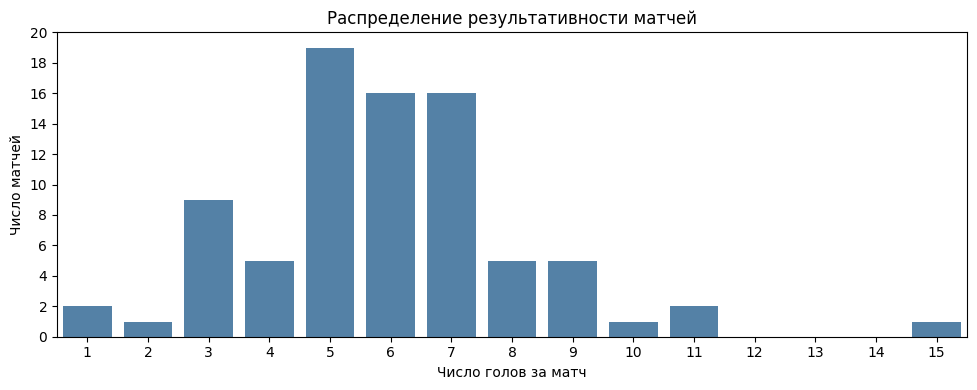

In [13]:
plt.figure(figsize=(10, 4))
sns.countplot(x=games["Total Score"], order=range(int(games["Total Score"].min()), int(games["Total Score"].max()) + 1), color="steelblue")
plt.xlabel("Число голов за матч")
plt.ylabel("Число матчей")
plt.title("Распределение результативности матчей")
plt.tight_layout()
plt.yticks(range(0, 21, 2))
plt.show()

6. Для поиска самых результативных и нерезультативных матчей использованы методы .min() и .max() для столбца Total Score. Затем отобраны все строки, значения которых совпадают с найденными экстремумами. Такой подход позволяет учитывать несколько матчей с одинаковым результатом.

Минимальная результативность — 1 гол:
- Montreal Canadiens — Tampa Bay Lightning (0:1, овертайм, 01.05.2026).
- Philadelphia Flyers — Pittsburgh Penguins (1:0, овертайм, 29.04.2026).
Максимальная результативность — 15 голов:
- Colorado Avalanche — Minnesota Wild (9:6, 03.05.2026).

Интересно, что оба матча с минимальной результативностью закончились в овертайме.

In [14]:
minimum = games["Total Score"].min()
maximum = games["Total Score"].max()
least = [gameInfo(i) for i in games.index[games["Total Score"] == minimum]]
most = [gameInfo(i) for i in games.index[games["Total Score"] == maximum]]
print("Минимум голов:", minimum, "\n", *least, sep="\n")
print("Максимум голов:", maximum, "\n", *most, sep="\n")

Минимум голов:
1


Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Максимум голов:
15


Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


7. Для каждого матча определено количество уникальных игроков, появлявшихся на льду. Использованы столбцы с полевыми игроками обеих команд, а также столбцы с вратарями. С помощью .stack() данные объединены в один список, .dropna() исключает пропуски, а .nunique() подсчитывает уникальные имена. Один игрок может многократно встречаться в записях разных событий, но учитываться должен только один раз. Максимальное количество уникальных имен в расчете составило 40 игроков в матче Montréal Canadiens — Buffalo Sabres, Game ID = 2025030216.

In [15]:
#имена считаем уникальными внутри матча
player_cols = ([f"Away Team's Player on the Ice #{k}" for k in range(1, 7)] +
               [f"Home Team's Player on the Ice #{k}" for k in range(1, 7)] +
               ["Away Team's Goalie", "Home Team's Goalie"])
def unique_players(group):
    return group[player_cols].stack().dropna().nunique()
player_counts = grouped.apply(unique_players, include_groups=False)
max_players = player_counts.max()
most_players = pd.DataFrame({
    "Game Info": [gameInfo(i) for i in player_counts.index[player_counts == max_players]],
    "Player Count": max_players}, index=player_counts.index[player_counts == max_players])
display(most_players)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


8.  Три типа событий: shot-on-goal (бросок в створ), goal (гол) и missed-shot (бросок мимо ворот). Всего получено 7 266 бросков. Для каждого броска рассчитано расстояние от точки его совершения до ближайшей точки створа ворот. При этом учитывается, что ворота имеют ширину 6 футов, а не представляют собой одну точку. В зависимости от расположения ворот и координат броска используется расстояние либо до ближайшей штанги, либо непосредственно до линии ворот. Для определения направления броска использованы поля Team Making the Play, Home Team и Home Team's Defending Side.

In [16]:
shot_types = ["shot-on-goal", "goal", "missed-shot"]
shots = events.loc[events["Play Type"].isin(shot_types)].copy()
home_shoots = shots["Team Making the Play"].eq(shots["Home Team"])
home_def_left = shots["Home Team's Defending Side"].eq("left")

shoots_right = home_shoots.eq(home_def_left)
X = np.where(shoots_right, 89, -89)
x = shots["X Coordinate on the Ice Rink"].to_numpy()
y = shots["Y Coordinate on the Ice Rink"].to_numpy()

dy = y - np.clip(y, -3, 3)
shots["Shot Length"] = np.sqrt((x - X)**2 + dy**2)
print("Бросков:", len(shots))
display(shots[["Game ID", "Play Type", "Shot Length"]].head().round(3))

Бросков: 7266


,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924


9. Две группы: точные броски (shot-on-goal и goal) и неточные (missed-shot). С помощью seaborn.histplot() построены распределения расстояний бросков до ворот. Параметр stat="density" позволяет сравнить именно форму распределений, а не абсолютное количество наблюдений, поскольку группы имеют разный размер. Медианные расстояния практически совпадают: типичные дистанции бросков в двух группах сходятся. При этом среднее расстояние точных бросков несколько выше, чем неточных. Это может объясняться наличием отдельных очень дальних бросков.

**Почему у точных бросков наблюдается длинный хвост со своей половины площадки?**

Одним из объяснений является ситуация, когда соперник снимает вратаря и заменяет его дополнительным полевым игроком. Тогда хоккеисты могут бросать по пустым воротам практически с любого расстояния, включая собственную половину площадки. Такие броски способны увеличивать среднее расстояние и формировать правый хвост распределения.
Кроме того, дальние броски могут быть связаны с игровыми эпизодами, в которых шайбу направляют в сторону ворот из своей зоны (пробросы).

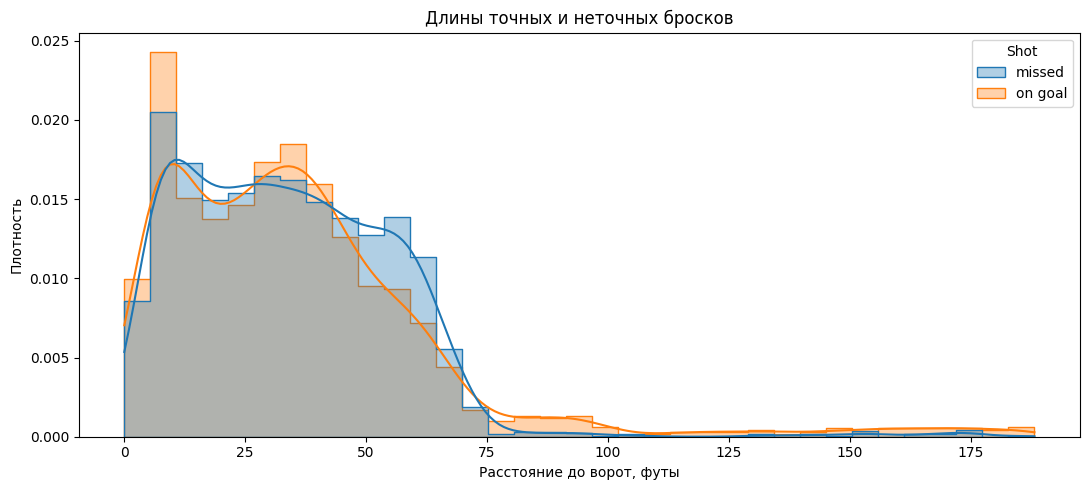

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.0,34.01,22.31,0.0,16.16,32.25,49.04,185.07
on goal,4623.0,36.21,30.00,0.0,15.00,31.83,47.01,188.22


In [17]:
shots["Shot"] = np.where(shots["Play Type"].eq("missed-shot"), "missed", "on goal")
plt.figure(figsize=(11, 5))
sns.histplot(data=shots, x="Shot Length", hue="Shot", bins=35,
             stat="density", common_norm=False, element="step", alpha=.35, kde=True)
plt.xlabel("Расстояние до ворот, футы")
plt.ylabel("Плотность")
plt.title("Длины точных и неточных бросков")
plt.tight_layout()
plt.show()
display(shots.groupby("Shot")["Shot Length"].describe().round(2))

10. Точными считаются события shot-on-goal и goal, поскольку гол также предполагает попадание шайбы в створ. Броски missed-shot учитываются в общем количестве попыток, но не в числе точных. События blocked-shot исключаются из расчета. В результате получено 164 значения: для двух команд в каждом из 82 матчей. Средняя доля точных бросков составила 63,92%, при этом минимальное значение равнялось 35,29%, а максимальное 86,05%. В среднем примерно две трети незаблокированных бросков достигали створа ворот. Однако показатель существенно различался между отдельными матчами, что может быть связано с игровой тактикой, качеством обороны соперника и выбором позиций для бросков. При этом точность попадания в створ не равнозначна результативности: бросок может попасть в створ, но быть отражён вратарём.

In [18]:
numshots = (shots.assign(OnGoal=shots["Play Type"].isin(["goal", "shot-on-goal"]))
            .groupby(["Game ID", "Team Making the Play"])
            .agg(Shots=("Play Type", "size"), OnGoal=("OnGoal", "sum")))
numshots["Share of Shots on Goal"] = numshots["OnGoal"] / numshots["Shots"]
display(numshots["Share of Shots on Goal"].round(3))
print("Средняя доля по командо-матчам:", numshots["Share of Shots on Goal"].mean().round(3))

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Средняя доля по командо-матчам: 0.639


11. Наибольшую среднюю точность показала Edmonton Oilers — около 70,6%, а наименьшую Pittsburgh Penguins — около 55,4%. Разница составляет примерно 15,2 процентного пункта. Результаты показывают заметные различия в способности команд направлять шайбу в створ ворот. При этом высокая точность бросков не обязательно означает высокую результативность. Например, Carolina Hurricanes находится среди пяти команд с самой низкой средней долей точных бросков, несмотря на достаточно высокое среднее количество голов за матч.

In [19]:
avgnumshots = numshots.groupby(level="Team Making the Play")["Share of Shots on Goal"].mean()
print("Пять лучших:")
display(avgnumshots.nlargest(5).round(3))
print("Пять худших:")
display(avgnumshots.nsmallest(5).round(3))

Пять лучших:


,Share of Shots on Goal
Team Making the Play,
Edmonton Oilers,0.706
Philadelphia Flyers,0.684
Dallas Stars,0.670
Minnesota Wild,0.656
Colorado Avalanche,0.653


Пять худших:


,Share of Shots on Goal
Team Making the Play,
Pittsburgh Penguins,0.554
Utah Mammoth,0.599
Carolina Hurricanes,0.615
Tampa Bay Lightning,0.626
Buffalo Sabres,0.626


12. Наибольшее среднее количество бросков в створ продемонстрировала Colorado Avalanche — около 32,15 за игру. При этом наибольшее среднее число голов показала Minnesota Wild — около 3,73 за игру. Команды, которые чаще бросают в створ ворот, не обязательно лидируют по количеству голов. Это может быть связано с различиями в эффективности реализации бросков.

In [22]:
shot_game_team = (shots.assign(Shot=shots["Play Type"].isin(["shot-on-goal", "goal"]).astype(int),
                               Goal=shots["Play Type"].eq("goal").astype(int))
                  .groupby(["Game ID", "Team Making the Play"])[["Shot", "Goal"]].sum())
avgshots = shot_game_team.groupby(level="Team Making the Play").mean()
display(avgshots.round(3))

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


13. **Наблюдается ли связь между числом бросков и голов?** Да, в данных наблюдается положительная линейная связь умеренной силы. В среднем команды, которые чаще бросают в створ ворот, склонны забивать больше голов. Однако точки заметно отклоняются от линии регрессии. Например, Minnesota Wild демонстрирует высокую результативность при среднем, а не максимальном количестве бросков.Число бросков объясняет лишь часть различий в результативности команд. Существенное значение могут иметь качество бросковых позиций, мастерство игроков и эффективность вратарей соперников.Кроме того, корреляция сама по себе не доказывает причинно-следственную связь.

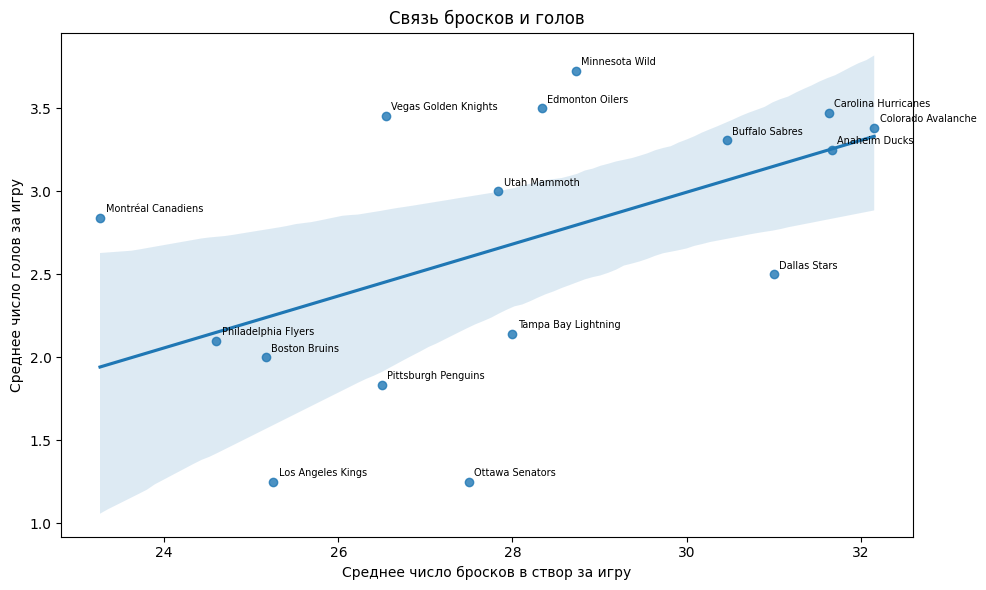

Корреляция Пирсона: 0.521


In [23]:
plt.figure(figsize=(10, 6))
sns.regplot(data=avgshots, x="Shot", y="Goal", ci=95)
for name, r in avgshots.iterrows():
    plt.annotate(name, (r["Shot"], r["Goal"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.xlabel("Среднее число бросков в створ за игру")
plt.ylabel("Среднее число голов за игру")
plt.title("Связь бросков и голов")
plt.tight_layout()
plt.show()
print("Корреляция Пирсона:", avgshots["Shot"].corr(avgshots["Goal"]).round(3))

14. В отличие от задания 10, здесь учитываются также заблокированные броски, поскольку требуется найти общее количество попыток. С помощью .groupby("Game ID").size() подсчитано количество соответствующих событий в каждом матче, после чего методом .idxmax() определён матч с максимальным значением. Максимальное количество попыток - 208 бросков. Это матч Carolina Hurricanes — Ottawa Senators (3:2, 20.04.2026), завершившийся во втором овертайме.
Большое количество бросков может быть связано с увеличенной продолжительностью встречи: матч с двумя овертаймами предоставляет командам больше игрового времени для совершения атакующих действий.

In [20]:
all_shot_types = ["shot-on-goal", "goal", "missed-shot", "blocked-shot"]
all_shots = events.loc[events["Play Type"].isin(all_shot_types)].copy()
all_shots_by_game = all_shots.groupby("Game ID").size()
idxmax = all_shots_by_game.idxmax()
print("Максимум попыток:", all_shots_by_game.max())
print(gameInfo(idxmax))

Максимум попыток: 208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


15. Получена пространственная визуализация всех попыток бросков в выбранном матче. Она позволяет оценить распределение атак по зонам площадки, сравнить расположение точных, неточных и заблокированных бросков и определить зоны, из которых были забиты голы. Визуализация отражает фактические координаты событий после преобразования и не позволяет сама по себе оценить вероятность гола без дополнительных расчетов.

In [3]:
from google.colab import files

uploaded = files.upload()

Saving rink.py to rink.py


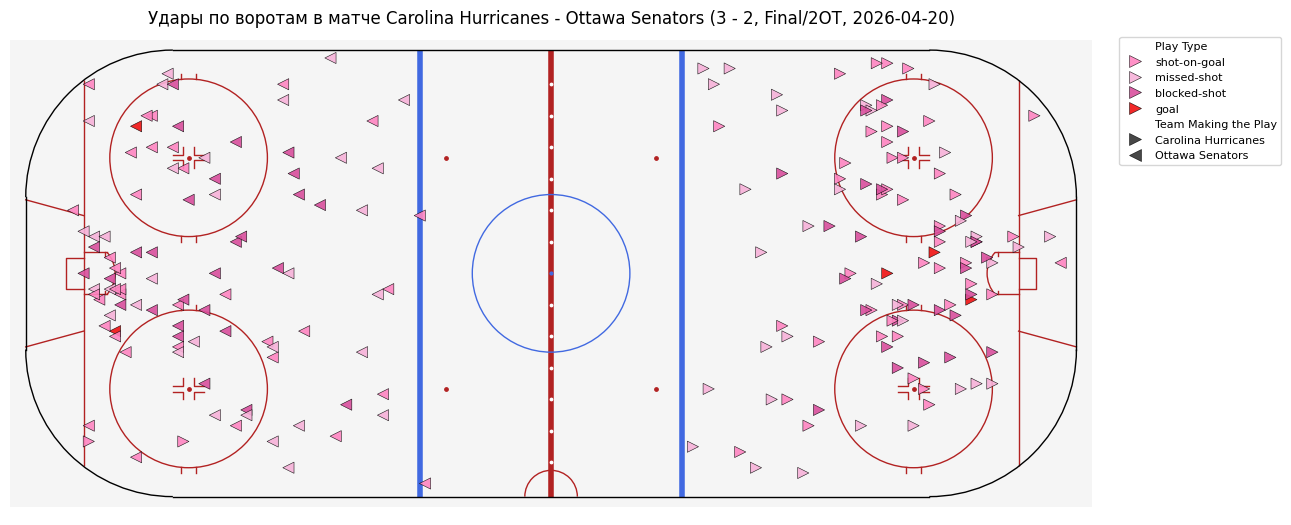

In [25]:
from rink import plot_rink

match_shots = all_shots.loc[all_shots["Game ID"].eq(idxmax)].copy()

home_team = match_shots["Home Team"].iloc[0]
away_team = match_shots["Away Team"].iloc[0]

odd = match_shots["Period"].mod(2).eq(1)

match_shots["Plot X"] = np.where(
    odd,
    -match_shots["X Coordinate on the Ice Rink"],
    match_shots["X Coordinate on the Ice Rink"]
)

match_shots["Plot Y"] = np.where(
    odd,
    -match_shots["Y Coordinate on the Ice Rink"],
    match_shots["Y Coordinate on the Ice Rink"]
)

pink_palette = {
    "goal": "#f01111",
    "shot-on-goal": "#ff85c1",
    "blocked-shot": "#d94f9d",
    "missed-shot": "#f7b2d9"
}

fig, ax = plt.subplots(figsize=(13, 6))
plt.sca(ax)
plot_rink(False)

sns.scatterplot(
    data=match_shots,
    x="Plot X",
    y="Plot Y",
    hue="Play Type",
    style="Team Making the Play",
    markers={
        away_team: "<",
        home_team: ">"
    },
    palette=pink_palette,
    s=65,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.4,
    ax=ax
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-103, 103)
ax.set_ylim(-46, 46)
ax.set_axis_off()
ax.set_title(f'Удары по воротам в матче {gameInfo(idxmax)}')
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title=None)

plt.tight_layout()
plt.show()

16. Лидером по количеству забитых шайб стал Brett Howden с 14 голами. Второе место занимает Pavel Dorofeyev с 12 голами, третье — Logan Stankoven с 11. Показатель характеризует результативность игрока в абсолютном выражении. Однако при его интерпретации необходимо учитывать, что команды провели разное количество матчей, поэтому общее количество голов зависит в том числе от продолжительности участия в плей-офф.

In [26]:
goals = events.loc[events["Play Type"].eq("goal")].copy()
goal_counts = goals["Player in the Event #1"].value_counts()
display(goal_counts.head(10).rename("Goals"))

,Goals
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Nathan MacKinnon,7
Taylor Hall,7
Mark Stone,7


17. Лидером стал Jack Eichel с 20 голевыми передачами, второе место занял Mitch Marner с 19 передачами.

In [27]:
assists = pd.concat([goals["Player in the Event #2"], goals["Player in the Event #3"]], ignore_index=True).dropna()
assist_counts = assists.value_counts()
display(assist_counts.head(10).rename("Assists"))

,Assists
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Taylor Hall,12
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Quinn Hughes,11
Kirill Kaprizov,11


18. Для расчета количества очков каждого хоккеиста суммированы показатели голов из задания 16 и голевых передач из задания 17. Наибольшее количество очков набрал Mitch Marner — 29 (10 голов и 19 передач). При этом лидирующий по голам Brett Howden занимает более низкую позицию в общем рейтинге. Это показывает, что итоговая результативность хоккеиста определяется не только количеством забитых шайб, но и участием в голевых комбинациях.

In [28]:
points = goal_counts.add(assist_counts, fill_value=0).astype(int).sort_values(ascending=False)
display(points.head(10).rename("Points"))

,Points
Mitch Marner,29
Jack Eichel,22
Jackson Blake,20
Taylor Hall,19
Shea Theodore,18
Nikolaj Ehlers,18
Brett Howden,18
Nick Suzuki,16
Lane Hutson,16
Pavel Dorofeyev,16


19. Лидером стал Jason Robertson, в среднем 5 бросков в створ за матч. В отличие от абсолютного количества бросков, данный показатель позволяет сравнивать игроков, которые провели разное количество встреч. Важно, что при расчете учитываются и матчи без бросков, если игрок принимал в них участие. В противном случае средний показатель был бы завышен.

In [29]:
skater_cols = [f"{side} Team's Player on the Ice #{k}" for side in ["Away", "Home"] for k in range(1, 7)]
players_on_ice = (events[["Game ID"] + skater_cols]
                 .melt(id_vars="Game ID", value_name="Player")
                 .dropna(subset=["Player"])[["Game ID", "Player"]].drop_duplicates())
played = players_on_ice.groupby("Player")["Game ID"].nunique()
shotter = events.loc[events["Play Type"].isin(["shot-on-goal", "goal"]), "Player in the Event #1"]
shots_per_game = shotter.value_counts().div(played).dropna().sort_values(ascending=False)
display(shots_per_game.head(10).round(3).rename("Shots per Game"))

,Shots per Game
Jason Robertson,5.000
Dylan Guenther,4.500
Nikita Kucherov,4.429
Matt Boldy,4.364
Quinton Byfield,4.250
Joel Eriksson Ek,4.000
Darren Raddysh,4.000
Alex Laferriere,3.750
David Pastrnak,3.667
Nathan MacKinnon,3.615


20. Наибольшее среднее количество силовых приёмов продемонстрировал Lawson Crouse (6,33 за матч). Полученные значения характеризуют интенсивность силовой отдельных хоккеистов. Однако показатель не позволяет напрямую оценивать эффективность силовых приемов или общий вклад игрока в результаты команды. Использование среднего значения за матч позволяет корректнее сравнивать хоккеистов с разным количеством проведённых игр.

In [30]:
hitters = events.loc[events["Play Type"].eq("hit"), "Player in the Event #1"]
hits_per_game = hitters.value_counts().div(played).dropna().sort_values(ascending=False)
display(hits_per_game.head(10).round(3).rename("Hits per Game"))

,Hits per Game
Lawson Crouse,6.333
Alexander Petrovic,6.000
Alex Turcotte,6.000
Yakov Trenin,5.667
Dylan Cozens,5.500
Vasily Podkolzin,5.333
Marcus Foligno,5.000
Carl Grundstrom,5.000
Ivan Barbashev,5.000
Owen Tippett,4.833


21. Всего выявлено 12 сочетаний «вратарь — матч» без пропущенных голов. Учитываются не только полные матчи, но и частичные выступления вратарей: выход на замену либо замена по ходу встречи. Гол, забитый в пустые ворота, не должен записываться в качестве пропущенного гола отсутствовавшему на льду вратарю. Список отражает вратарей, для которых в данных имеется хотя бы одно выступление без зафиксированных пропущенных шайб. При этом такой результат не обязательно означает полноценный «сухой матч».

In [31]:
home_g = (events[["Game ID", "Home Team's Goalie"]].rename(columns={"Home Team's Goalie": "Goalie"}))
away_g = (events[["Game ID", "Away Team's Goalie"]].rename(columns={"Away Team's Goalie": "Goalie"}))
goalie_appearances = pd.concat([home_g, away_g], ignore_index=True).dropna().drop_duplicates()
goals_against = goals[["Game ID", "Team Making the Play", "Home Team", "Away Team",
                       "Home Team's Goalie", "Away Team's Goalie"]].copy()
goals_against["Goalie"] = np.where(goals_against["Team Making the Play"].eq(goals_against["Home Team"]),
                                  goals_against["Away Team's Goalie"], goals_against["Home Team's Goalie"])
conceded = goals_against.dropna(subset=["Goalie"]).groupby(["Game ID", "Goalie"]).size().rename("Goals Against")
goalie_games = goalie_appearances.merge(conceded.reset_index(), on=["Game ID", "Goalie"], how="left")
goalie_games["Goals Against"] = goalie_games["Goals Against"].fillna(0).astype(int)
clean_goalie_games = goalie_games.loc[goalie_games["Goals Against"].eq(0)].sort_values(["Goalie", "Game ID"])
display(clean_goalie_games)
print("Уникальные вратари:")
print(*sorted(clean_goalie_games["Goalie"].unique()), sep="\n")

,Game ID,Goalie,Goals Against
99,2025030126,Andrei Vasilevskiy,0
110,2025030146,Arturs Silovs,0
170,2025030413,Brandon Bussi,0
173,2025030416,Brandon Bussi,0
106,2025030142,Dan Vladar,0
24,2025030146,Dan Vladar,0
15,2025030131,Frederik Andersen,0
56,2025030221,Frederik Andersen,0
161,2025030314,Frederik Andersen,0
13,2025030126,Jakub Dobes,0


Уникальные вратари:
Andrei Vasilevskiy
Arturs Silovs
Brandon Bussi
Dan Vladar
Frederik Andersen
Jakub Dobes
Joonas Korpisalo
Scott Wedgewood


22. Топ 15 игроков по совмещению бросок и гол, т е по созданным бросковым возможностям, которые они создали сами себе и их реализация в гол или пас.

Для определения наиболее активных атакующих игроков были рассчитаны количество незаблокированных бросков, забитых голов и голевых передач каждого хоккеиста. На основе полученных данных составлен рейтинг 15 игроков с наибольшим количеством собственных бросковых попыток.

Также рассчитана эффективность реализации бросков как отношение числа голов к общему количеству попыток, выраженное в процентах. Также учтены очки по системе «гол + пас», позволяющие оценить общий результативный вклад игрока.


In [32]:
shots = events[
    events["Play Type"].isin(["shot-on-goal", "missed-shot", "goal"])
].copy()

attempts = shots.groupby("Player in the Event #1").size()

goals = (
    events[events["Play Type"] == "goal"]
    ["Player in the Event #1"]
    .value_counts()
)

goal_events = events[events["Play Type"] == "goal"]

assists = pd.concat([
    goal_events["Player in the Event #2"],
    goal_events["Player in the Event #3"]
]).value_counts()

top_players = pd.DataFrame({
    "Shot Attempts": attempts,
    "Goals": goals,
    "Assists": assists
}).fillna(0)

top_players["Goals + Assists"] = (
    top_players["Goals"] + top_players["Assists"]
)

top_players["Conversion (%)"] = (
    top_players["Goals"] / top_players["Shot Attempts"] * 100
)

top15 = top_players.nlargest(15, "Shot Attempts")

display(top15.round(2))

,Shot Attempts,Goals,Assists,Goals + Assists,Conversion (%)
Pavel Dorofeyev,95.0,12.0,4.0,16.0,12.63
Andrei Svechnikov,89.0,6.0,5.0,11.0,6.74
Mitch Marner,85.0,10.0,19.0,29.0,11.76
Jack Eichel,84.0,2.0,20.0,22.0,2.38
Nikolaj Ehlers,79.0,8.0,10.0,18.0,10.13
Taylor Hall,78.0,7.0,12.0,19.0,8.97
Logan Stankoven,77.0,11.0,5.0,16.0,14.29
Nathan MacKinnon,75.0,7.0,8.0,15.0,9.33
Jackson Blake,74.0,7.0,13.0,20.0,9.46
Matt Boldy,74.0,7.0,6.0,13.0,9.46
